In [5]:
import pandas as pd

df = pd.read_csv("../data/raw/listings.csv.gz")
print(df.shape)
df[["price", "room_type", "neighbourhood_cleansed",
    "latitude", "longitude", "accommodates",
    "review_scores_rating", "number_of_reviews"]].head()

(37451, 90)


,price,room_type,neighbourhood_cleansed,latitude,longitude,accommodates,review_scores_rating,number_of_reviews
0,$66.00,Private room,XII Monte Verde,41.873180,12.457210,3,4.60,27
1,$134.00,Entire home/apt,XII Monte Verde,41.872334,12.456810,8,4.41,48
2,$62.23,Private room,VIII Appia Antica,41.871360,12.482150,1,4.80,5
3,$194.00,Entire home/apt,I Centro Storico,41.895447,12.491181,2,4.87,306
4,$220.87,Entire home/apt,I Centro Storico,41.908230,12.452930,5,4.59,205


In [6]:
df.isna().mean().sort_values(ascending=False).head(15)

neighborhood_overview           1.000000
host_since                      1.000000
host_response_time              1.000000
host_thumbnail_url              1.000000
host_acceptance_rate            1.000000
host_response_rate              1.000000
host_verifications              1.000000
neighbourhood                   1.000000
host_total_listings_count       1.000000
host_neighbourhood              1.000000
calendar_updated                1.000000
instant_bookable                1.000000
neighbourhood_group_cleansed    1.000000
bathrooms                       1.000000
source                          0.885797
dtype: float64

In [7]:
df.dtypes.value_counts()

float64    37
str        29
int64      24
Name: count, dtype: int64

In [8]:
df["price"] = (df["price"]
               .str.replace("$", "", regex=False)
               .str.replace(",", "", regex=False)
               .astype(float))
df["price"].describe()

count    33933.000000
mean       254.340713
std        467.663470
min         17.120000
25%        134.450000
50%        188.500000
75%        273.330000
max      37474.000000
Name: price, dtype: float64

In [9]:
df["price"].quantile([0.01, 0.05, 0.95, 0.99, 0.995, 0.999])

0.010      47.00960
0.050      82.00000
0.950     549.00000
0.990    1178.08800
0.995    1863.70860
0.999    5802.60304
Name: price, dtype: float64

In [10]:
df.sort_values("price", ascending=False)[
    ["price", "room_type", "accommodates", "neighbourhood_cleansed"]
].head(20)

,price,room_type,accommodates,neighbourhood_cleansed
35507,37474.00,Entire home/apt,2,I Centro Storico
34760,20566.00,Entire home/apt,5,I Centro Storico
26902,15816.45,Entire home/apt,2,IV Tiburtina
19931,15710.30,Entire home/apt,6,VII San Giovanni/Cinecittà
25376,15417.30,Entire home/apt,6,V Prenestino/Centocelle
29326,13915.50,Entire home/apt,4,XIII Aurelia
29327,13728.50,Entire home/apt,4,XIII Aurelia
34333,13427.56,Private room,2,VIII Appia Antica
34426,13274.66,Private room,2,VIII Appia Antica
34428,13274.66,Private room,2,VIII Appia Antica


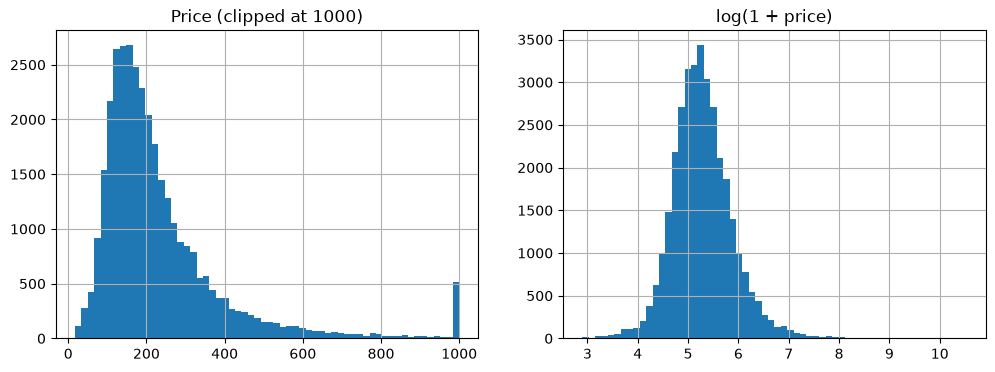

In [15]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["price"].clip(upper=1000).hist(bins=60, ax=ax[0])
ax[0].set_title("Price (clipped at 1000)")
np.log1p(df["price"]).hist(bins=60, ax=ax[1])
ax[1].set_title("log(1 + price)")
plt.savefig("../reports/figures/price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


In [16]:
df_clean = df[df["price"].between(20, 2000)].copy()
print(len(df), "->", len(df_clean))

37451 -> 33769


EDA

In [18]:
df_clean["log_price"] = np.log1p(df_clean["price"])

df_clean.groupby("room_type")["price"].agg(["count", "median", "mean"]).round(1)

,count,median,mean
room_type,,,
Entire home/apt,25281,205.4,254.5
Hotel room,154,203.5,237.2
Private room,8262,139.0,169.9
Shared room,72,53.9,90.5


In [19]:
(df_clean.groupby("neighbourhood_cleansed")["price"]
         .agg(["count", "median"])
         .sort_values("median", ascending=False)
         .round(1))

,count,median
neighbourhood_cleansed,,
I Centro Storico,17597,235.7
XIII Aurelia,2395,174.0
II Parioli/Nomentano,2159,171.0
XII Monte Verde,1757,156.7
VII San Giovanni/Cinecittà,2832,150.0
VIII Appia Antica,1035,144.0
XIV Monte Mario,706,143.0
XI Arvalia/Portuense,675,135.5
XV Cassia/Flaminia,480,135.0


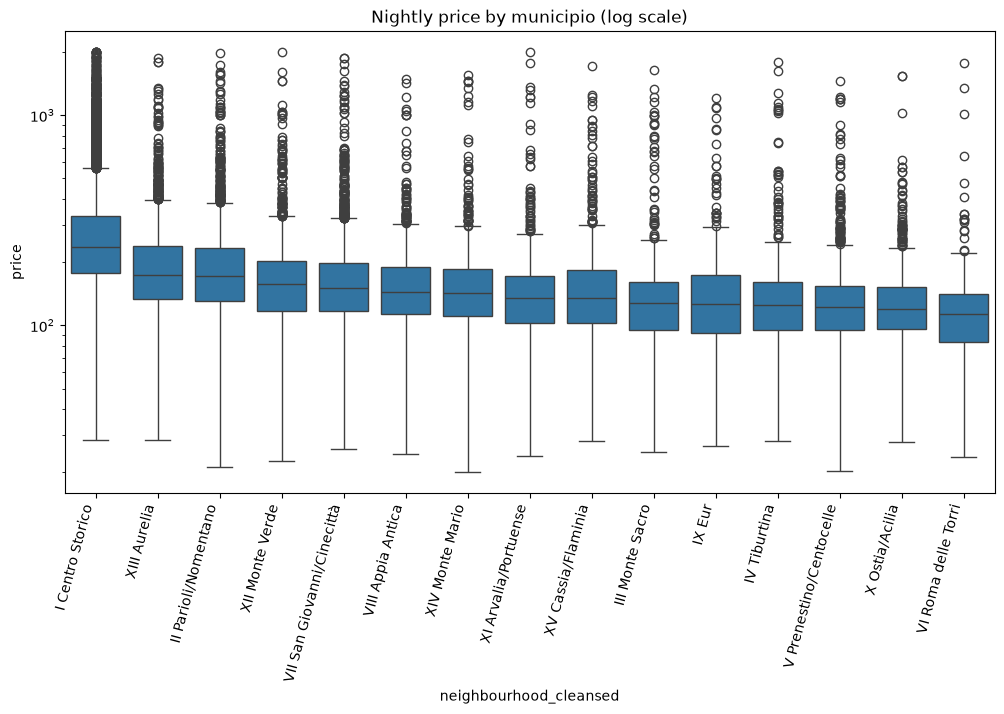

In [20]:
import seaborn as sns

order = (df_clean.groupby("neighbourhood_cleansed")["price"]
                 .median().sort_values(ascending=False).index)

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean, x="neighbourhood_cleansed", y="price", order=order)
plt.yscale("log")
plt.xticks(rotation=75, ha="right")
plt.title("Nightly price by municipio (log scale)")
plt.savefig("../reports/figures/price_by_neighbourhood.png", dpi=150, bbox_inches="tight")
plt.show()